# 카카오맵 카페정보 수집
### 참고 URL = https://map.kakao.com/

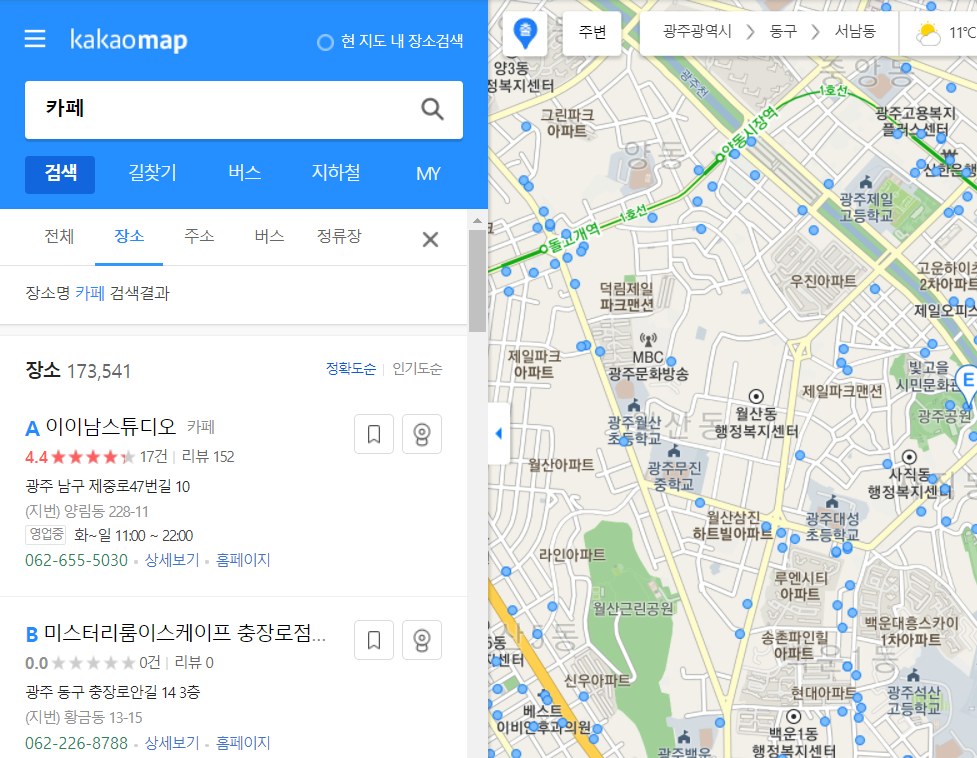

In [ ]:
pip install --upgrade selenium

In [ ]:
pip install webdriver_manager

In [ ]:
from selenium import webdriver as wb
from bs4 import BeautifulSoup as bs
import time
from selenium.webdriver.common.by import By

In [ ]:
driver = wb.Chrome()
driver.get("https://map.kakao.com/")

In [ ]:
div = driver.find_element(By.CSS_SELECTOR, ".layer_body")
div.click()

In [ ]:
search = driver.find_element(By.CSS_SELECTOR, "#search\\.keyword\\.query")
search.send_keys("쏘카")

In [ ]:
search_btn = driver.find_element(By.CSS_SELECTOR, "#search\\.keyword\\.submit")
search_btn.click()

In [ ]:
btnmore = driver.find_element(By.CSS_SELECTOR, "#info\\.search\\.place\\.more")
btnmore.click()

In [ ]:
page = driver.find_elements(By.CSS_SELECTOR, "#info\\.search\\.page > div > a")

In [ ]:
driver = wb.Chrome()
driver.get("https://map.kakao.com/")

div = driver.find_element(By.CSS_SELECTOR, ".layer_body")
div.click()

search = driver.find_element(By.CSS_SELECTOR, "#search\\.keyword\\.query")
search.send_keys("쏘카")

search_btn = driver.find_element(By.CSS_SELECTOR, "#search\\.keyword\\.submit")
search_btn.click()

btnmore = driver.find_element(By.CSS_SELECTOR, "#info\\.search\\.place\\.more")
btnmore.click()

page = driver.find_elements(By.CSS_SELECTOR, "#info\\.search\\.page > div > a")

try :
    while True :
        for i in range(6) :
            if(i < 5):
                page[i].click()
                time.sleep(1)
                soup = bs(driver.page_source,"lxml")
                ad = soup.select(".ico_ad")
                for i in ad :
                    i.extract()
                title = soup.select("a.link_name")
                for i in title :
                    print(i.text)
                time.sleep(1)
            else :
                btnNext = driver.find_element_by_css_selector("#info\.search\.page\.next")
                btnNext.click()
                time.sleep(1)
except :
    print("검색종료")

In [ ]:
from selenium import webdriver
from selenium.webdriver.chrome.service import Service
from selenium.webdriver.common.by import By
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC
from selenium.common.exceptions import NoSuchElementException
from webdriver_manager.chrome import ChromeDriverManager
from bs4 import BeautifulSoup as bs
import pandas as pd
import time

# 웹 드라이버 초기화
driver = webdriver.Chrome(service=Service(ChromeDriverManager().install()))

# 카카오맵의 쏘카 검색 페이지 열기
driver.get("https://map.kakao.com/")

# 지도 레이어의 검색창 클릭
div = WebDriverWait(driver, 10).until(
    EC.element_to_be_clickable((By.CSS_SELECTOR, ".layer_body"))
)
div.click()

# 검색어 입력
search = WebDriverWait(driver, 10).until(
    EC.presence_of_element_located((By.CSS_SELECTOR, "#search\\.keyword\\.query"))
)
search.send_keys("쏘카")

# 검색 버튼 클릭
search_btn = WebDriverWait(driver, 10).until(
    EC.element_to_be_clickable((By.CSS_SELECTOR, "#search\\.keyword\\.submit"))
)
search_btn.click()

# '더보기' 버튼 클릭
btnmore = WebDriverWait(driver, 10).until(
    EC.element_to_be_clickable((By.CSS_SELECTOR, "#info\\.search\\.place\\.more"))
)
btnmore.click()

# 페이지 내 모든 지점 정보를 담을 리스트
data = []

def get_data_from_current_page():
    """현재 페이지의 지점 데이터를 추출하여 data 리스트에 추가하는 함수"""
    soup = bs(driver.page_source, "lxml")
    # 광고 아이콘 제거
    ad = soup.select(".ico_ad")
    for ad_icon in ad:
        ad_icon.decompose()

    # 지점 이름 추출
    title_elements = soup.select("a.link_name")
    for element in title_elements:
        data.append({"Name": element.text.strip()})
        print(f"지점 이름 수집: {element.text.strip()}")

try:
    while True:
        # 현재 페이지에서 지점 데이터 수집
        get_data_from_current_page()
        
        try:
            # "다음 페이지" 버튼 클릭
            next_button = WebDriverWait(driver, 10).until(
                EC.element_to_be_clickable((By.CSS_SELECTOR, "#info\\.search\\.page\\.next"))
            )
            next_button.click()
            time.sleep(2)  # 페이지가 로드될 때까지 대기
        except NoSuchElementException:
            # 더 이상 "다음 페이지" 버튼이 없으면 종료
            print("다음 페이지가 없습니다. 크롤링을 종료합니다.")
            break
except Exception as e:
    print(f"크롤링 도중 오류 발생: {e}")

finally:
    # 드라이버 종료
    driver.quit()

# 데이터프레임으로 변환하여 CSV 파일로 저장
df = pd.DataFrame(data)
df.to_csv('socar_places.csv', index=False, encoding='utf-8-sig')
print("CSV 파일로 저장되었습니다.")


In [ ]:
from selenium import webdriver as wb
from selenium.webdriver.common.by import By
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC
from bs4 import BeautifulSoup as bs
import time

# 웹드라이버 초기화
driver = wb.Chrome()
driver.get("https://map.kakao.com/")

# 검색창에 '쏘카' 검색
search = WebDriverWait(driver, 10).until(
    EC.presence_of_element_located((By.CSS_SELECTOR, "#search\\.keyword\\.query"))
)
search.send_keys("쏘카")

# '검색' 버튼 클릭
search_btn = WebDriverWait(driver, 10).until(
    EC.element_to_be_clickable((By.CSS_SELECTOR, "#search\\.keyword\\.submit"))
)
driver.execute_script("arguments[0].click();", search_btn)

# '더보기' 버튼 클릭하여 상세 검색결과 열기
btnmore = WebDriverWait(driver, 10).until(
    EC.element_to_be_clickable((By.CSS_SELECTOR, "#info\\.search\\.place\\.more"))
)
driver.execute_script("arguments[0].click();", btnmore)

# 페이지 크롤링
def crawl_pages(start_page, end_page):
    for page in range(start_page, end_page + 1):
        print(f"크롤링 페이지: {page}")
        # 현재 페이지의 페이지 소스 가져오기
        soup = bs(driver.page_source, "lxml")
        
        # 광고 배너 제거
        ad_elements = soup.select(".ico_ad")
        for ad in ad_elements:
            ad.extract()
        
        # 타이틀 추출 및 출력
        titles = soup.select("a.link_name")
        for title in titles:
            print(title.text)
        
        if page < end_page:
            try:
                # 페이지 전환을 위해 스크롤
                driver.execute_script("window.scrollTo(0, document.body.scrollHeight);")
                time.sleep(1)  # 스크롤 후 잠시 대기
                
                # 페이지 이동
                next_button = WebDriverWait(driver, 10).until(
                    EC.element_to_be_clickable((By.CSS_SELECTOR, "#info\\.search\\.page\\.next"))
                )
                driver.execute_script("arguments[0].click();", next_button)
                time.sleep(2)  # 페이지 전환 대기

            except Exception as e:
                print(f"다음 페이지로 이동 중 오류 발생: {e}")
                break

try:
    while True:
        # 크롤링할 페이지 범위 설정
        crawl_pages(start_page=1, end_page=5)
        crawl_pages(start_page=6, end_page=10)
        crawl_pages(start_page=11, end_page=15)
        crawl_pages(start_page=16, end_page=20)
        crawl_pages(start_page=21, end_page=25)
        crawl_pages(start_page=26, end_page=30)
        crawl_pages(start_page=31, end_page=34)
        break  # 모든 페이지 범위를 크롤링했으므로 루프 종료

except Exception as e:
    print(f"크롤링 도중 오류 발생: {e}")

finally:
    driver.quit()
